# AS — Recomendação de Treinos Personalizados em Academia (notebook final)

**Fundamentos de Inteligência Artificial — ADS/ULBRA — 2026/2 — Vinicius Casagrande**

Este é o notebook final do projeto. Ele vai **dos dados brutos até a decisão do modelo** em uma única execução, sem depender dos notebooks anteriores:

| Seção | O que faz | Critério da rubrica |
|---|---|---|
| 1 | Problema, público e o que mudou desde a AP2 | 1 |
| 2–3 | Regera a base do zero, reproduz o tratamento e faz o diagnóstico de qualidade | 2 |
| 4–5 | Features, divisão, baseline, modelos testados e escolha do modelo final | 3 |
| 6–7 | Métricas, comparação com o baseline, o que cada erro significa e instabilidade | 4 |
| 8 | Regra de segurança como **encaminhamento ao professor**, com as métricas separadas | 4 e 5 |
| 9 | Explicabilidade: as regras que a árvore final aprendeu | 5 |
| 10 | Auditoria de viés por subgrupo, com e sem a idade | 5 |
| 11 | Limitações, riscos e próximos passos | 5 |

O histórico de cada decisão está nos notebooks `atividade4` a `atividade15` e no README.

**Configuração final (medida aqui):** árvore de decisão com `max_depth=6`, **sem a variável idade**, mais uma regra de segurança que **encaminha ao professor** os alunos com restrição física e iniciantes, ou sem equipamento.

Duas mudanças em relação à proposta da Atividade 15 (árvore `max_depth=5` balanced sem idade) saíram deste notebook, na seção 5:
- **Profundidade 6 em vez de 5.** A árvore impressa mostrou que, com 5 níveis, ela não chega à pergunta "é iniciante?" no ramo de hipertrofia.
- **Sem `balanced`.** Na profundidade 6 ele não muda nada.

In [1]:
# Colab: clona o repositório se os arquivos não estiverem presentes
import os
if not os.path.exists('dataset_academia_tratado.csv'):
    !git clone https://github.com/Vinicasagrande87/fundamentos_ia.git
    %cd fundamentos_ia

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, cross_validate, cross_val_predict, RepeatedStratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, recall_score, precision_score, make_scorer,
                             classification_report, confusion_matrix)
import gerar_dataset
from gerar_dataset import recomenda_treino

pd.set_option('display.width', 200)
print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)
print('Versões fixadas em requirements.txt. Com outra versão do scikit-learn, o split único pode variar em 1 aluno.')

scikit-learn 1.9.1 | pandas 3.1.1 | numpy 2.5.4
Versões fixadas em requirements.txt. Com outra versão do scikit-learn, o split único pode variar em 1 aluno.


## 1. Problema, público e o que mudou desde a AP2

**Problema.** Montar o treino inicial de um aluno exige cruzar objetivo, experiência, dias disponíveis, restrição física e equipamento. O sistema sugere uma de 4 categorias de treino a partir do perfil preenchido na matrícula. É o **ponto de partida** do aluno, não a progressão semana a semana.

| Saída | Significado |
|---|---|
| Treino A | Musculação / hipertrofia |
| Treino B | Cardio + circuito |
| Treino C | Funcional |
| Treino D | Peso corporal adaptado: o treino "seguro" |

**Público.** Professores de educação física, que recebem a sugestão e decidem. O aluno é o afetado.

**Por que o erro importa.** O erro mais caro é um **falso negativo de Treino D**: um aluno que precisava do treino adaptado (por restrição física, falta de equipamento ou pouca experiência) recebe um treino mais exigente. Na vida real, isso é risco de lesão e de desistência no primeiro mês. Por isso a métrica principal é o **recall de Treino D**: de cada 100 alunos que precisavam do treino adaptado, quantos o receberam.

**O que mudou desde a AP2.**
- **Número de referência.** A AP2 apresentou 0,90 de acurácia num único split. Esse número foi sorte do sorteio. O número de referência agora é a média da validação cruzada.
- **Balanceamento.** O `class_weight='balanced'` parecia melhorar o recall de D. A comparação pareada da Atividade 15 mostrou que não melhora, e ele saiu.
- **Idade.** A idade era usada pela árvore como atalho, sem fazer parte da regra real. Ela saiu do modelo.
- **Profundidade.** Ler as regras da árvore mostrou um ramo que ela não tinha profundidade para resolver. A profundidade passou de 5 para 6.
- **Pergunta respondida (conceitual).** O projeto deixou de ser "qual modelo acerta mais?" e passou a ser "**onde** o modelo erra, **com quem**, e o que um professor precisa revisar".

## 2. Dados: origem e reprodução a partir do zero

**Origem.** Os dados são **sintéticos**: não há aluno real. Eles foram gerados por `gerar_dataset.py` (seed 1053), com distribuições escolhidas pelo autor para parecer uma academia típica (Atividade 4). O rótulo `treino_recomendado` vem de uma **regra escrita pelo autor** (`recomenda_treino`). Depois, 8% dos rótulos (24 alunos) são trocados ao acaso para simular exceções.

**Condições de "coleta".** Ninguém mediu nada. O que o modelo aprende é a regra do autor mais o ruído, e por isso nenhum número deste notebook vale para alunos reais sem nova validação.

A célula abaixo **regera a base** e confere que ela é idêntica ao CSV do repositório.

In [3]:
regerada = gerar_dataset.gera(1053)
original = pd.read_csv('dataset_academia.csv')
print('Base regerada idêntica a dataset_academia.csv:', regerada.equals(original))
print('Linhas:', original.shape[0], '| colunas:', original.shape[1])
original.head()

Base regerada idêntica a dataset_academia.csv: True
Linhas: 300 | colunas: 8


,aluno_id,idade,objetivo,nivel_experiencia,dias_disponiveis_semana,restricao_fisica,equipamento_disponivel,treino_recomendado
0,1,32,Condicionamento,Avancado,2,Nenhuma,Completo,Treino C
1,2,37,Hipertrofia,Iniciante,4,Nenhuma,Completo,Treino A
2,3,24,Condicionamento,Iniciante,3,Lombar,Limitado,Treino D
3,4,31,Emagrecimento,Iniciante,4,Joelho,Nenhum,Treino D
4,5,22,Condicionamento,Intermediario,3,Nenhuma,Completo,Treino C


## 3. Tratamento e diagnóstico de qualidade

O tratamento da Atividade 8 tem 3 passos, todos determinísticos (nenhum aprende estatística dos dados, então não há risco de vazamento antes do split):

| Passo | Por quê | Efeito no resultado |
|---|---|---|
| `aluno_id` sai das features | É um número sequencial sem relação com o perfil | Evita que o modelo decore IDs |
| Padronizar o texto (`strip` + `title`) | O diagnóstico da Atividade 5 encontrou inconsistência de grafia | Evita que "iniciante" e "Iniciante" virem categorias diferentes |
| Categorias ordinais (nível, equipamento) | São ordens naturais | Documental: o one-hot abaixo não usa a ordem |

In [4]:
trat = original.copy()
for c in ['objetivo', 'nivel_experiencia', 'restricao_fisica', 'equipamento_disponivel', 'treino_recomendado']:
    trat[c] = trat[c].str.strip().str.title()
df = pd.read_csv('dataset_academia_tratado.csv')
print('Tratamento reproduzido idêntico a dataset_academia_tratado.csv:', trat.equals(df))

print('\nValores ausentes:', int(df.isna().sum().sum()), '| linhas duplicadas:', df.drop(columns='aluno_id').duplicated().sum(),
      '(perfis repetidos são possíveis numa base com 6 variáveis; não são cópias do mesmo aluno)')
print('Idade:', df['idade'].min(), 'a', df['idade'].max(), 'anos')

df['regra'] = [recomenda_treino(r.objetivo, r.nivel_experiencia, r.dias_disponiveis_semana, r.restricao_fisica,
                                r.equipamento_disponivel) for r in df.itertuples()]
df['ruido'] = df['regra'] != df['treino_recomendado']
print('Rótulos ruidosos (diferentes da regra):', df['ruido'].sum(), 'de', len(df),
      '-> teto de acurácia de qualquer modelo:', round(1 - df['ruido'].mean(), 2))

dist = df['treino_recomendado'].value_counts().sort_index()
pd.DataFrame({'alunos': dist, '%': (dist / len(df) * 100).round(1)})

Tratamento reproduzido idêntico a dataset_academia_tratado.csv: True

Valores ausentes: 0 | linhas duplicadas: 7 (perfis repetidos são possíveis numa base com 6 variáveis; não são cópias do mesmo aluno)
Idade: 16 a 51 anos
Rótulos ruidosos (diferentes da regra): 24 de 300 -> teto de acurácia de qualquer modelo: 0.92


,alunos,%
treino_recomendado,,
Treino A,74,24.7
Treino B,54,18.0
Treino C,80,26.7
Treino D,92,30.7


**Leitura do diagnóstico.**
- **Sem ausentes.** Não houve imputação, então nada foi inventado no tratamento.
- **Desbalanceamento moderado.** Treino D tem 92 alunos (31%) e Treino B só 54 (18%). Um modelo que chuta sempre a classe maior já acerta 31%: esse é o baseline.
- **Ruído de 8%.** Nenhum modelo passa de ~0,92 de acurácia, porque 24 rótulos contradizem a própria regra.
- **Como a base limita o modelo.** As combinações raras têm poucos exemplos. É o caso de "iniciante + restrição + emagrecimento + 3 ou mais dias", e é exatamente nelas que o modelo vai errar (seções 8 e 10). A limitação da base vira limitação do modelo.

## 4. Features, divisão e forma de avaliar

- **Features.** One-hot nas 4 variáveis categóricas, mais `dias_disponiveis_semana`. A **idade fica de fora** do modelo final. Ela só aparece nas versões de comparação, para mostrar o efeito de removê-la.
- **Split único 80/20 estratificado** (`random_state=42`, o mesmo da AP2), mantido para continuidade com a AP2.
- **Número de referência:** validação cruzada estratificada (5 folds), **repetida 10 vezes** com sorteios diferentes (10×5). Cada aluno é previsto por um modelo que não o viu no treino.
- **Comparação justa.** Todos os modelos são avaliados nas **mesmas** 10 repetições. Para comparar dois modelos, conto em quantas das 10 repetições um ganha do outro.
- **Três números por modelo:**
  - acurácia;
  - recall de Treino D na base inteira;
  - recall de Treino D **fora da cobertura da regra de segurança**. É onde o modelo decide sozinho (seção 8 explica por quê).

In [5]:
y = df['treino_recomendado']
CAT = ['objetivo', 'nivel_experiencia', 'restricao_fisica', 'equipamento_disponivel']
X_com_idade = pd.get_dummies(df[['idade', 'dias_disponiveis_semana'] + CAT], columns=CAT)
X = X_com_idade.drop(columns='idade')          # features do modelo final
print('Features do modelo final:', X.shape[1], list(X.columns))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
Xi_train, Xi_test = X_com_idade.loc[X_train.index], X_com_idade.loc[X_test.index]
print('Treino:', len(X_train), '| teste:', len(X_test), '| Treino D no teste:', (y_test == 'Treino D').sum())

# Regra de segurança (seção 8): restrição física + iniciante, ou sem equipamento -> revisão do professor
cob = ((df['restricao_fisica'] != 'Nenhuma') & (df['nivel_experiencia'] == 'Iniciante')) | (df['equipamento_disponivel'] == 'Nenhum')
print('Alunos cobertos pela regra de segurança:', cob.sum(), '| fora da cobertura:', (~cob).sum())

CLASSES = ['Treino A', 'Treino B', 'Treino C', 'Treino D']
recall_D = lambda yt, yp: recall_score(yt, yp, labels=['Treino D'], average=None)[0]
precisao_D = lambda yt, yp: precision_score(yt, yp, labels=['Treino D'], average=None, zero_division=0)[0]
FOLDS = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0).split(X, y))

def avalia(modelo, Xa):
    # 10 repetições de validação cruzada 5 folds: uma previsão fora da amostra por aluno em cada repetição
    linhas = []
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        for r in range(10):
            p = pd.Series(cross_val_predict(modelo, Xa, y, cv=FOLDS[r * 5:(r + 1) * 5]), index=df.index)
            linhas.append({'acurácia': accuracy_score(y, p), 'recall D': recall_D(y, p),
                           'recall D fora da regra': recall_D(y[~cob], p[~cob]),
                           'falsos neg. D fora da regra': ((y == 'Treino D') & ~cob & (p != 'Treino D')).sum()})
        treino = cross_validate(modelo, Xa, y, cv=FOLDS, return_train_score=True)['train_score'].mean()
    return pd.DataFrame(linhas), treino

Features do modelo final: 14 ['dias_disponiveis_semana', 'objetivo_Condicionamento', 'objetivo_Emagrecimento', 'objetivo_Hipertrofia', 'nivel_experiencia_Avancado', 'nivel_experiencia_Iniciante', 'nivel_experiencia_Intermediario', 'restricao_fisica_Joelho', 'restricao_fisica_Lombar', 'restricao_fisica_Nenhuma', 'restricao_fisica_Ombro', 'equipamento_disponivel_Completo', 'equipamento_disponivel_Limitado', 'equipamento_disponivel_Nenhum']
Treino: 240 | teste: 60 | Treino D no teste: 18
Alunos cobertos pela regra de segurança: 72 | fora da cobertura: 228


## 5. Modelos testados e escolha do modelo final

Primeiro, a trajetória do projeto: o baseline, a árvore da AP2, a da Atividade 15 e a rede neural da Atividade 13, todos medidos do mesmo jeito.

In [6]:
arvore = lambda d, **kw: DecisionTreeClassifier(max_depth=d, random_state=42, **kw)
mlp = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(16,), max_iter=3000, random_state=42))
candidatos = {
    'Baseline (classe mais frequente)':              (DummyClassifier(strategy='most_frequent'), X),
    'Árvore d=5, com idade (AP2)':                    (arvore(5), X_com_idade),
    'Árvore d=5 balanced, com idade (Ativ. 15)':      (arvore(5, class_weight='balanced'), X_com_idade),
    'Árvore d=5 balanced, sem idade (proposta Ativ. 15)': (arvore(5, class_weight='balanced'), X),
    'Rede neural MLP (16), sem idade':                (mlp, X),
    'Árvore d=6 balanced, sem idade':                 (arvore(6, class_weight='balanced'), X),
    'Árvore d=6, sem idade (FINAL)':                  (arvore(6), X),
}
REP, linhas = {}, []
for nome, (m, Xa) in candidatos.items():
    REP[nome], treino = avalia(m, Xa)
    Xtr, Xte = Xa.loc[X_train.index], Xa.loc[X_test.index]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        p = m.fit(Xtr, y_train).predict(Xte)
    linhas.append({'modelo': nome, 'acurácia split único': accuracy_score(y_test, p),
                   **REP[nome].mean().to_dict(), 'desvio acurácia': REP[nome]['acurácia'].std(),
                   'acurácia no treino': treino})
resultados = pd.DataFrame(linhas).set_index('modelo')
resultados.round(3)

,acurácia split único,acurácia,recall D,recall D fora da regra,falsos neg. D fora da regra,desvio acurácia,acurácia no treino
modelo,,,,,,,
Baseline (classe mais frequente),0.300,0.307,1.000,1.000,0.0,0.000,0.307
"Árvore d=5, com idade (AP2)",0.900,0.826,0.767,0.593,12.2,0.012,0.904
"Árvore d=5 balanced, com idade (Ativ. 15)",0.900,0.835,0.760,0.597,12.1,0.009,0.901
"Árvore d=5 balanced, sem idade (proposta Ativ. 15)",0.900,0.844,0.782,0.597,12.1,0.007,0.897
"Rede neural MLP (16), sem idade",0.917,0.857,0.861,0.817,5.5,0.010,0.931
"Árvore d=6 balanced, sem idade",0.900,0.859,0.830,0.870,3.9,0.007,0.933
"Árvore d=6, sem idade (FINAL)",0.917,0.860,0.840,0.890,3.3,0.012,0.933


**Por que a profundidade mudou: o que a árvore de profundidade 5 não consegue perguntar.**

Lendo as regras da árvore `max_depth=5` sem idade, o ramo *hipertrofia, sem restrição, com equipamento* termina em Treino A, qualquer que seja a experiência. Na regra real há uma exceção: **iniciante com até 2 dias vai para Treino D**. Para chegar a essa pergunta, a árvore precisa de 6 níveis:
1. Emagrecimento?
2. Condicionamento?
3. Restrição?
4. Sem equipamento?
5. Dias ≤ 2?
6. Iniciante?

Com 5 níveis ela não chega lá. Os iniciantes de hipertrofia com poucos dias recebem Treino A: carga para quem tem pouca experiência e pouco tempo. É um erro de **capacidade** do modelo, não de falta de dados, e por isso a rede neural (mais flexível) acertava esses casos.

A célula abaixo varia só a profundidade.

In [7]:
prof = []
for d in [4, 5, 6, 7, 8, None]:
    r, treino = avalia(arvore(d), X)
    folhas = arvore(d).fit(X, y).get_n_leaves()
    prof.append({'max_depth': 'sem limite' if d is None else d, 'folhas': folhas, **r.mean().to_dict(), 'acurácia no treino': treino})
pd.DataFrame(prof).set_index('max_depth').round(3)

,folhas,acurácia,recall D,recall D fora da regra,falsos neg. D fora da regra,acurácia no treino
max_depth,,,,,,
4,15,0.860,0.836,0.673,9.8,0.873
5,26,0.850,0.818,0.680,9.6,0.899
6,38,0.860,0.840,0.890,3.3,0.933
7,47,0.849,0.815,0.897,3.1,0.938
8,54,0.840,0.822,0.897,3.1,0.942
sem limite,66,0.837,0.820,0.897,3.1,0.948


In [8]:
def compara(a, b):
    out = []
    for met in ['acurácia', 'recall D', 'recall D fora da regra']:
        d = REP[b][met] - REP[a][met]
        out.append({'comparação': f'{b}  x  {a}', 'métrica': met, 'diferença média': d.mean(),
                    'ganha (repetições)': (d > 0).sum(), 'empata': (d == 0).sum(), 'perde': (d < 0).sum()})
    return out

FINAL = 'Árvore d=6, sem idade (FINAL)'
pd.DataFrame(compara('Árvore d=5 balanced, sem idade (proposta Ativ. 15)', FINAL)
             + compara('Rede neural MLP (16), sem idade', FINAL)
             + compara('Árvore d=5, com idade (AP2)', FINAL)).set_index(['comparação', 'métrica']).round(3)

diferença média  ganha (repetições)  empata  perde
comparação                                         métrica                                                                   
Árvore d=6, sem idade (FINAL)  x  Árvore d=5 ba... acurácia                          0.016                   9       0      1
                                                   recall D                          0.059                  10       0      0
                                                   recall D fora da regra            0.293                  10       0      0
Árvore d=6, sem idade (FINAL)  x  Rede neural M... acurácia                          0.003                   5       2      3
                                                   recall D                         -0.021                   2       3      5
                                                   recall D fora da regra            0.073                  10       0      0
Árvore d=6, sem idade (FINAL)  x  Árvore d=5, c... acurácia                          0.034                  10       0      0
                                                   recall D                          0.073                   9       1      0
                                                   recall D fora da regra            0.297                  10       0      0

**Decisão: árvore `max_depth=6`, sem idade, sem balanceamento.**

- **Contra o baseline.** O baseline acerta ~31% (sempre Treino D). Ele tem recall de D de 1,00, mas manda todo mundo para o treino adaptado: é inútil como recomendação. A árvore final acerta ~86%, quase **3 vezes mais**, e pega 84 de cada 100 alunos que precisam do Treino D.
- **Por que a profundidade 6.**
  - A acurácia quase não muda entre 4 e 6 (0,85 a 0,86). O que separa as profundidades é o **recall de D fora da regra**: 0,67 a 0,68 com 4 ou 5 níveis, contra **0,89 com 6**. É o ramo da hipertrofia sendo resolvido.
  - De 7 em diante, o recall de D não melhora mais e a acurácia de validação cai: as folhas a mais só decoram ruído.
- **Por que não a rede neural.**
  - Na acurácia, a árvore de profundidade 6 empata com a rede (5 vitórias, 2 empates, 3 derrotas).
  - No recall de D da base inteira, a rede é um pouco melhor (−0,02 para a árvore). Essa vantagem está **dentro** da cobertura da regra, onde quem decide é o professor.
  - **Fora da regra**, onde o modelo decide sozinho, a árvore ganha nas 10 repetições (+0,07).
  - A rede não mostra as regras que usou. Foi lendo as regras da árvore que encontrei o problema da profundidade: numa rede neural eu não teria visto.
- **Por que sem `balanced`.** Na Atividade 15, o balanced não melhorou o recall de D. Na profundidade 6, ele não muda nada mensurável (linha "d=6 balanced" da primeira tabela). Ficou o modelo mais simples.
- **Por que sem idade.** A regra real não usa idade, e a auditoria da seção 10 mostra o efeito de tirá-la.
- **Suposições do algoritmo e se elas valem aqui.**
  - A árvore supõe que a resposta pode ser descrita por **cortes sucessivos em uma variável de cada vez**. Isso vale aqui, porque a regra de geração é uma sequência de "se... então".
  - Ela **não** supõe escala nem distribuição normal, então não precisa normalizar.
  - A suposição que falha é a de **ter exemplos suficientes em cada folha**. Com 300 alunos, algumas folhas têm poucos alunos e podem refletir ruído (seção 9).
- **Overfitting.** A acurácia no treino (~0,93) passa um pouco do teto de 0,92, então a árvore já ajusta alguns rótulos ruidosos. A seção 9 mostra onde isso acontece. É um sinal leve, porque a validação continua no nível mais alto da tabela de profundidades.

## 6. Avaliação do modelo final

Previsões **fora da amostra** para os 300 alunos: cada aluno é previsto por uma árvore que não o viu no treino (`cross_val_predict`, 5 folds). As métricas desta seção e das seções 8 e 10 usam essas previsões.

In [9]:
final = arvore(6)
df['previsto'] = cross_val_predict(final, X, y, cv=5)
df['previsto_com_idade'] = cross_val_predict(arvore(5, class_weight='balanced'), X_com_idade, y, cv=5)
p_base = cross_val_predict(DummyClassifier(strategy='most_frequent'), X, y, cv=5)

print(classification_report(y, df['previsto'], digits=3))
cm = pd.DataFrame(confusion_matrix(y, df['previsto'], labels=CLASSES), index=CLASSES, columns=CLASSES)
print('Matriz de confusão (linhas = real, colunas = previsto):')
print(cm)
fn_D = ((y == 'Treino D') & (df['previsto'] != 'Treino D')).sum()
print(f'\nFalsos negativos de Treino D: {fn_D} de {(y == "Treino D").sum()} alunos que precisavam do treino adaptado')
print('Para onde foram:', df.loc[(y == 'Treino D') & (df['previsto'] != 'Treino D'), 'previsto'].value_counts().to_dict())

              precision    recall  f1-score   support

    Treino A      0.840     0.851     0.846        74
    Treino B      0.839     0.870     0.855        54
    Treino C      0.901     0.912     0.907        80
    Treino D      0.852     0.815     0.833        92

    accuracy                          0.860       300
   macro avg      0.858     0.862     0.860       300
weighted avg      0.860     0.860     0.860       300

Matriz de confusão (linhas = real, colunas = previsto):
          Treino A  Treino B  Treino C  Treino D
Treino A        63         1         3         7
Treino B         2        47         1         4
Treino C         2         3        73         2
Treino D         8         5         4        75

Falsos negativos de Treino D: 17 de 92 alunos que precisavam do treino adaptado
Para onde foram: {'Treino A': 8, 'Treino B': 5, 'Treino C': 4}


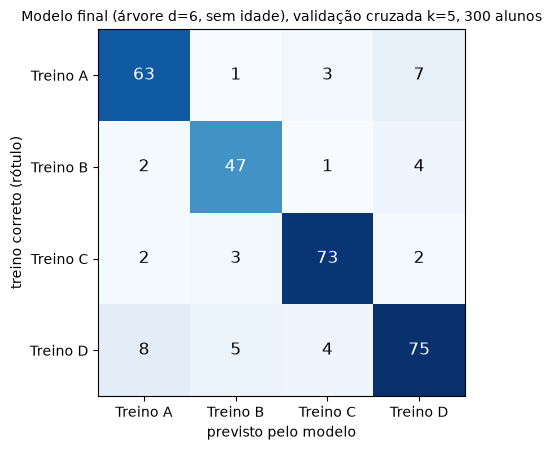

In [10]:
fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.imshow(cm.values, cmap='Blues')
for i in range(4):
    for j in range(4):
        v = cm.values[i, j]
        ax.text(j, i, v, ha='center', va='center', fontsize=12, color='white' if v > cm.values.max() * 0.55 else '#0b0b0b')
ax.set_xticks(range(4), CLASSES); ax.set_yticks(range(4), CLASSES)
ax.set_xlabel('previsto pelo modelo'); ax.set_ylabel('treino correto (rótulo)')
ax.set_title('Modelo final (árvore d=6, sem idade), validação cruzada k=5, 300 alunos', fontsize=10)
plt.tight_layout(); plt.savefig('matriz_confusao_final.png', dpi=150, bbox_inches='tight'); plt.show()

**O que olhar na figura.** A diagonal são os acertos. O número que importa está na **última linha, fora da diagonal**: são os alunos que precisavam do Treino D e receberam outro.

**O que cada erro significa na academia:**

| Erro | Na vida real | Custo |
|---|---|---|
| Precisava de D, recebeu A/B/C | Iniciante com restrição recebe treino de carga ou circuito | **Alto:** lesão, dor, desistência |
| Recebeu D sem precisar | Aluno apto recebe treino leve demais | Baixo: o professor ajusta na 1ª semana |
| Troca entre A, B e C | Treino com foco diferente do objetivo | Médio: progresso mais lento |

## 7. Instabilidade: o mesmo modelo em 30 divisões diferentes

Com 60 alunos no teste, cada aluno vale 1,7 ponto de acurácia. A célula abaixo mostra quanto o resultado depende do sorteio.

In [11]:
accs, recs = [], []
for s in range(30):
    a, b, c, d = train_test_split(X, y, test_size=0.2, random_state=s, stratify=y)
    pp = arvore(6).fit(a, c).predict(b)
    accs.append(accuracy_score(d, pp)); recs.append(recall_D(d, pp))
inst = pd.DataFrame({'acurácia': accs, 'recall de D': recs})
inst.describe().loc[['mean', 'std', 'min', 'max']].round(3)

,acurácia,recall de D
mean,0.866,0.859
std,0.039,0.077
min,0.800,0.667
max,0.950,1.000


**Leitura.** O mesmo modelo, com a mesma configuração, varia vários pontos só pela troca de quem cai no teste. Por isso um split único isolado (como o 0,90 da AP2) **não** é o número a reportar. O número de referência é a média da validação cruzada.

## 8. Regra de segurança como encaminhamento ao professor

**Regra:** aluno com **restrição física e iniciante**, ou **sem equipamento**, **não recebe recomendação automática**. A saída para ele é *"revisão do professor (sugestão: Treino D)"*.

**O problema de medir isso (feedback da Atividade 14).** Se a regra sobrescreve o modelo, o recall de D do sistema deixa de medir o modelo. A regra copia um trecho da regra que **gerou os rótulos**. Dentro da cobertura, ela acerta por construção: só "erra" onde o rótulo é ruído. Por isso as métricas abaixo são **separadas**:
1. **Fora da cobertura**, onde o modelo decide sozinho. Essa é a métrica honesta do modelo.
2. **Dentro da cobertura**, o que a árvore teria feito e o que a regra faz.
3. **A cobertura em si**, que é um custo: quantos alunos vão para a fila do professor.

In [12]:
cob = ((df['restricao_fisica'] != 'Nenhuma') & (df['nivel_experiencia'] == 'Iniciante')) | (df['equipamento_disponivel'] == 'Nenhum')
df['saida_sistema'] = df['previsto'].where(~cob, 'Revisão do professor (sugestão: Treino D)')
sistema_como_D = df['previsto'].where(~cob, 'Treino D')
isD = y == 'Treino D'

print(f'Cobertura da regra: {cob.sum()} de {len(df)} alunos ({cob.mean():.0%}) vão para revisão do professor')
print('Para todos os cobertos a regra de geração manda Treino D:', (df.loc[cob, 'regra'] == 'Treino D').all(),
      '-> dentro da cobertura, o acerto da regra é circular')
print('Previsões da árvore que a regra altera:', (cob & (df['previsto'] != 'Treino D')).sum())

def bloco(nome, mask, prev):
    yt, yp = y[mask], prev[mask]
    return {'recorte': nome, 'alunos': mask.sum(), 'alunos D': (yt == 'Treino D').sum(), 'acurácia': accuracy_score(yt, yp),
            'recall D': recall_D(yt, yp), 'falsos neg. D': ((yt == 'Treino D') & (yp != 'Treino D')).sum()}

sep = pd.DataFrame([
    bloco('Baseline (sempre D), base inteira', pd.Series(True, index=df.index), pd.Series(p_base, index=df.index)),
    bloco('Modelo sozinho, base inteira', pd.Series(True, index=df.index), df['previsto']),
    bloco('FORA da cobertura: modelo decide (métrica honesta)', ~cob, df['previsto']),
    bloco('DENTRO da cobertura: o que a árvore faria', cob, df['previsto']),
    bloco('DENTRO da cobertura: regra (circular nesta base)', cob, sistema_como_D),
    bloco('Sistema agregado (NÃO usar como métrica do modelo)', pd.Series(True, index=df.index), sistema_como_D),
]).set_index('recorte')
sep.round(3)

Cobertura da regra: 72 de 300 alunos (24%) vão para revisão do professor
Para todos os cobertos a regra de geração manda Treino D: True -> dentro da cobertura, o acerto da regra é circular
Previsões da árvore que a regra altera: 12


,alunos,alunos D,acurácia,recall D,falsos neg. D
recorte,,,,,
"Baseline (sempre D), base inteira",300,92,0.307,1.000,0
"Modelo sozinho, base inteira",300,92,0.860,0.815,17
FORA da cobertura: modelo decide (métrica honesta),228,30,0.912,0.833,5
DENTRO da cobertura: o que a árvore faria,72,62,0.694,0.806,12
DENTRO da cobertura: regra (circular nesta base),72,62,0.861,1.000,0
Sistema agregado (NÃO usar como métrica do modelo),300,92,0.900,0.946,5


In [13]:
print('Exemplos da saída do sistema:')
df.loc[[*df[cob].index[:2], *df[~cob].index[:3]],
       ['idade', 'objetivo', 'nivel_experiencia', 'dias_disponiveis_semana', 'restricao_fisica',
        'equipamento_disponivel', 'saida_sistema', 'treino_recomendado']]

Exemplos da saída do sistema:


,idade,objetivo,nivel_experiencia,dias_disponiveis_semana,restricao_fisica,equipamento_disponivel,saida_sistema,treino_recomendado
2,24,Condicionamento,Iniciante,3,Lombar,Limitado,Revisão do professor (sugestão: Treino D),Treino D
3,31,Emagrecimento,Iniciante,4,Joelho,Nenhum,Revisão do professor (sugestão: Treino D),Treino D
0,32,Condicionamento,Avancado,2,Nenhuma,Completo,Treino C,Treino C
1,37,Hipertrofia,Iniciante,4,Nenhuma,Completo,Treino A,Treino A
4,22,Condicionamento,Intermediario,3,Nenhuma,Completo,Treino C,Treino C


**Leitura.**
- **O número que reporto como desempenho do modelo é o de fora da cobertura.** Ali estão os alunos sem a combinação de risco, e o modelo decide sozinho.
- **Dentro da cobertura, a árvore sozinha erraria mais.** É lá que estão as combinações raras e os rótulos ruidosos dos iniciantes. A regra fecha esses casos, mas nesta base o ganho está garantido por construção. Com alunos reais, ele só pode ser medido contra a decisão do professor.
- **A cobertura é custo, não acerto.** Cerca de 1 em cada 4 alunos vai para a fila do professor. Numa academia real, isso é tempo de trabalho e precisa caber na rotina.
- **Os falsos negativos de D que sobram estão todos fora da regra.** São alunos que precisam do treino adaptado por terem **poucos dias (≤2)**, combinados com restrição em quem não é iniciante ou com emagrecimento. A regra de segurança não cobre esses casos, e a tabela abaixo mostra quais são.

In [14]:
fn_fora = df[(~cob) & isD & (df['previsto'] != 'Treino D')]
print('Falsos negativos de D fora da cobertura:', len(fn_fora))
fn_fora[['objetivo', 'nivel_experiencia', 'dias_disponiveis_semana', 'restricao_fisica', 'equipamento_disponivel',
         'regra', 'ruido', 'previsto']].sort_values(['objetivo', 'nivel_experiencia'])

Falsos negativos de D fora da cobertura: 5


,objetivo,nivel_experiencia,dias_disponiveis_semana,restricao_fisica,equipamento_disponivel,regra,ruido,previsto
285,Condicionamento,Intermediario,2,Lombar,Completo,Treino D,False,Treino C
290,Condicionamento,Intermediario,1,Lombar,Completo,Treino D,False,Treino C
123,Emagrecimento,Avancado,2,Lombar,Completo,Treino D,False,Treino B
121,Emagrecimento,Iniciante,2,Nenhuma,Completo,Treino D,False,Treino B
142,Emagrecimento,Iniciante,2,Nenhuma,Completo,Treino D,False,Treino B


## 9. Explicabilidade: o que a árvore final pergunta

Abaixo estão as perguntas que a árvore final faz a cada aluno, treinada com a base inteira (a versão que seria usada em produção). Cada linha é um teste `variável <= valor`. Nas variáveis one-hot, `<= 0.50` significa "não é" e `> 0.50` significa "é".

In [15]:
final_prod = arvore(6).fit(X, y)
regras_txt = export_text(final_prod, feature_names=list(X.columns))
print(regras_txt)
print('Nós que usam idade:', regras_txt.count('idade'))

imp = pd.Series(final_prod.feature_importances_, X.columns).sort_values(ascending=False)
imp[imp > 0].round(3).to_frame('importância')

|--- objetivo_Emagrecimento <= 0.50
|   |--- objetivo_Condicionamento <= 0.50
|   |   |--- restricao_fisica_Nenhuma <= 0.50
|   |   |   |--- nivel_experiencia_Iniciante <= 0.50
|   |   |   |   |--- dias_disponiveis_semana <= 2.50
|   |   |   |   |   |--- class: Treino D
|   |   |   |   |--- dias_disponiveis_semana >  2.50
|   |   |   |   |   |--- class: Treino C
|   |   |   |--- nivel_experiencia_Iniciante >  0.50
|   |   |   |   |--- dias_disponiveis_semana <= 2.50
|   |   |   |   |   |--- restricao_fisica_Joelho <= 0.50
|   |   |   |   |   |   |--- class: Treino D
|   |   |   |   |   |--- restricao_fisica_Joelho >  0.50
|   |   |   |   |   |   |--- class: Treino A
|   |   |   |   |--- dias_disponiveis_semana >  2.50
|   |   |   |   |   |--- class: Treino D
|   |   |--- restricao_fisica_Nenhuma >  0.50
|   |   |   |--- equipamento_disponivel_Nenhum <= 0.50
|   |   |   |   |--- dias_disponiveis_semana <= 2.50
|   |   |   |   |   |--- nivel_experiencia_Iniciante <= 0.50
|   |   |   |   

,importância
restricao_fisica_Nenhuma,0.225
objetivo_Emagrecimento,0.179
nivel_experiencia_Iniciante,0.154
dias_disponiveis_semana,0.148
objetivo_Condicionamento,0.127
equipamento_disponivel_Nenhum,0.125
restricao_fisica_Joelho,0.012
restricao_fisica_Lombar,0.009
nivel_experiencia_Avancado,0.007
equipamento_disponivel_Limitado,0.007


**Leitura.**
- **As variáveis são as mesmas da regra real, em outra ordem.**
  - As 6 features mais importantes correspondem exatamente às 5 variáveis da regra de geração: restrição, objetivo, nível, dias e equipamento.
  - A árvore começa por "o objetivo é emagrecimento?" e "é condicionamento?", e só depois pergunta restrição, nível e dias.
  - A regra real começa por equipamento. A árvore escolhe a pergunta que mais separa as classes nesta base, não a ordem de quem escreveu a regra.
- **O ramo que justificou a profundidade 6.** Em *hipertrofia → sem restrição → com equipamento → dias ≤ 2*, a árvore agora pergunta **"é iniciante?"** e manda o iniciante para Treino D. É a exceção da regra real que a árvore de profundidade 5 não alcançava.
- **Duas folhas perigosas, encontradas só porque a árvore é legível.**
  - *Hipertrofia + restrição (joelho) + iniciante + ≤2 dias → Treino A.*
  - *Condicionamento + restrição + iniciante + ≤2 dias → Treino A.*
  - A regra real manda os dois perfis para Treino D. São folhas com poucos alunos que se ajustaram a rótulos ruidosos: é o overfitting leve visto na seção 5.
  - Na vida real, seria **um iniciante com restrição recebendo treino de carga**.
  - Os dois perfis estão **dentro da cobertura da regra de segurança**, então nunca recebem a previsão automática. Esse é o argumento mais concreto para manter a regra, e não deixar a árvore decidir sozinha nesses casos.
- **Comparação com a AP2.** Na árvore da AP2 (Atividades 9 e 10), perguntas como "idade ≤ 19,5?" decidiam entre Treino A e D. A regra real nunca usa idade, e agora nenhum nó usa.
- **Explicabilidade na prática.** O professor pode seguir o caminho de um aluno nessas linhas e ver **por que** ele recebeu aquela sugestão. Essa é a principal razão para preferir a árvore à rede neural.

## 10. Auditoria de viés: o modelo erra igual para todos?

Recall de Treino D por subgrupo: o modelo da Atividade 15 (d=5 balanced, com idade) contra o modelo final (d=6, sem idade). A pergunta é se algum grupo de alunos é sistematicamente pior atendido.

In [16]:
df['faixa_idade'] = pd.cut(df['idade'], [0, 24, 34, 100], labels=['16-24 anos', '25-34 anos', '35+ anos'])
NOMES = {'faixa_idade': 'Idade', 'nivel_experiencia': 'Nível', 'restricao_fisica': 'Restrição',
         'equipamento_disponivel': 'Equipamento', 'objetivo': 'Objetivo'}
linhas = []
for col in NOMES:
    for g, s in df.groupby(col, observed=True):
        nD = (s['treino_recomendado'] == 'Treino D').sum()
        linhas.append({'variável': NOMES[col], 'subgrupo': str(g), 'alunos': len(s), 'alunos D': nD,
                       'recall D Ativ. 15': recall_D(s['treino_recomendado'], s['previsto_com_idade']) if nD else np.nan,
                       'recall D final (sem idade)': recall_D(s['treino_recomendado'], s['previsto']) if nD else np.nan,
                       'acurácia final': accuracy_score(s['treino_recomendado'], s['previsto']),
                       '% rótulos ruidosos': s['ruido'].mean() * 100})
sub = pd.DataFrame(linhas)
sub.round(3)

,variável,subgrupo,alunos,alunos D,recall D Ativ. 15,recall D final (sem idade),acurácia final,% rótulos ruidosos
0,Idade,16-24 anos,89,27,0.667,0.815,0.854,8.989
1,Idade,25-34 anos,130,40,0.875,0.825,0.869,7.692
2,Idade,35+ anos,81,25,0.680,0.800,0.852,7.407
3,Nível,Avancado,39,5,0.800,0.600,0.923,0.000
4,Nível,Iniciante,161,71,0.789,0.845,0.807,12.422
5,Nível,Intermediario,100,16,0.625,0.750,0.920,4.000
6,Restrição,Joelho,34,21,0.905,0.857,0.794,11.765
7,Restrição,Lombar,34,21,0.667,0.619,0.647,8.824
8,Restrição,Nenhuma,208,38,0.711,0.895,0.909,7.212
9,Restrição,Ombro,24,12,0.833,0.833,0.833,8.333


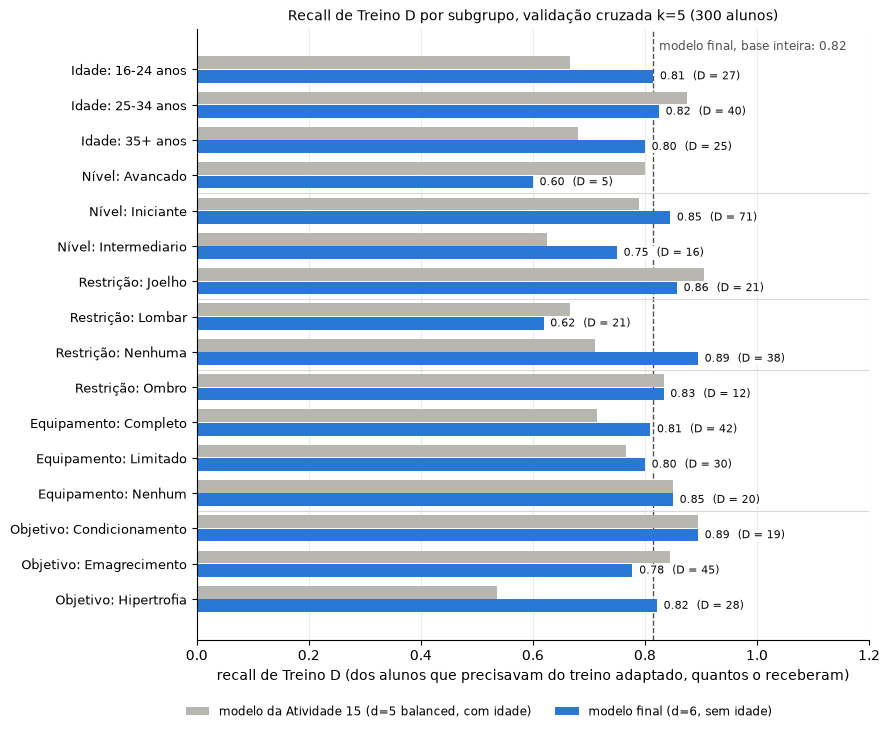

In [17]:
plot = sub.iloc[::-1].reset_index(drop=True)
yy = np.arange(len(plot))
fig, ax = plt.subplots(figsize=(9, 7.4))
ax.barh(yy + 0.19, plot['recall D Ativ. 15'], height=0.36, color='#b7b6b1', label='modelo da Atividade 15 (d=5 balanced, com idade)', zorder=2)
ax.barh(yy - 0.19, plot['recall D final (sem idade)'], height=0.36, color='#2a78d6', label='modelo final (d=6, sem idade)', zorder=2)
geral = recall_D(y, df['previsto'])
ax.axvline(geral, color='#52514e', ls='--', lw=1, zorder=1)
ax.text(geral + 0.01, len(plot) - 0.45, f'modelo final, base inteira: {geral:.2f}', fontsize=8.5, color='#52514e')
for i, r in plot.iterrows():
    ax.text(r['recall D final (sem idade)'] + 0.012, i - 0.19, f"{r['recall D final (sem idade)']:.2f}  (D = {r['alunos D']})",
            va='center', fontsize=8, color='#0b0b0b', zorder=3, bbox=dict(facecolor='white', edgecolor='none', pad=0.5))
ax.set_yticks(yy, [f"{r['variável']}: {r['subgrupo']}" for _, r in plot.iterrows()], fontsize=9)
for s_ in [2.5, 6.5, 8.5, 11.5]:
    ax.axhline(s_, color='#d9d8d4', lw=0.8)
ax.set_xlim(0, 1.2); ax.grid(axis='x', alpha=0.25)
ax.set_xlabel('recall de Treino D (dos alunos que precisavam do treino adaptado, quantos o receberam)')
ax.set_title('Recall de Treino D por subgrupo, validação cruzada k=5 (300 alunos)', fontsize=10)
ax.legend(loc='upper center', bbox_to_anchor=(0.42, -0.09), ncol=2, fontsize=8.5, frameon=False)
for s_ in ['top', 'right']:
    ax.spines[s_].set_visible(False)
plt.tight_layout(); plt.savefig('recall_D_subgrupo_final.png', dpi=150, bbox_inches='tight'); plt.show()

**O que olhar na figura.** As barras azuis são o modelo final. Cada barra que fica **à esquerda da linha tracejada** representa um grupo pior atendido do que a média.

**Leitura da auditoria.**
- **Quem está representado.** Só alunos de 16 a 51 anos, com 3 tipos de restrição sem grau de gravidade, numa base sintética. Idosos, gestantes, cardiopatas e pessoas com mais de uma restrição **não existem na base**.
- **Variáveis que funcionam como proxy.**
  - `idade`: atalho espúrio, já removido.
  - `restricao_fisica`: dado de saúde, sensível pela LGPD.
  - `equipamento_disponivel`: indica a condição econômica de quem treina em casa sem equipamento.
- **O que mudou com o modelo final.**
  - **Idade:** a diferença entre faixas etárias praticamente desapareceu. O recall de D era 0,67, 0,88 e 0,68 (16-24, 25-34, 35+) e passou a 0,82, 0,83 e 0,80.
  - **Hipertrofia:** o recall de D subiu de 0,54 para 0,82.
  - **Atenção à causa.** Duas coisas mudaram juntas (tirar a idade e aprofundar a árvore). A seção 5 mede o efeito da profundidade isolada.
- **Quem continua pior atendido.**
  - **Lombar:** recall de D 0,62 e acurácia 0,65. É o pior grupo do modelo.
  - **Intermediários e avançados** que precisam de D, com 16 e 5 alunos.
  - São alunos com restrição ou com poucos dias que **não** caem na regra de segurança, porque não são iniciantes.
  - Consequência real: um aluno intermediário com dor lombar e pouco tempo é o perfil mais provável de receber um treino inadequado.
  - **Próximo passo:** estender a regra para "restrição lombar, qualquer nível". Isso só deve ser feito depois de medir quantos alunos a mais iriam para a fila do professor.
- **Ruído desigual.** Os iniciantes têm 12% de rótulos ruidosos, contra 4% dos intermediários. O ruído foi sorteado, mas caiu mais em quem já é o grupo de maior risco.
- **Decisões humanas passadas.** Os rótulos são decisões de **uma pessoa** (o autor) sobre qual treino cada perfil deve receber. Qualquer viés dessa regra é aprendido e repetido pelo modelo. Numa base real, o rótulo seria a decisão dos professores da academia, e o mesmo cuidado valeria.

## 11. Limitações, riscos e próximos passos

**Limitações (declaradas, não escondidas).**
1. **Base sintética.** O modelo recupera a regra do autor. Nada aqui foi validado com alunos reais.
2. **Pergunta mais fácil que a de um app real.** Esta é a resposta à pergunta do feedback da Atividade 14.
   - O projeto decide só o **ponto de partida**, a partir de um perfil estático.
   - Ele não sabe se a recomendação funcionou (aderência, dor, evolução), porque isso exige histórico de treinos.
   - Ele cobre o "primeiro dia" que apps como o Fitbod fazem mal, mas não substitui a progressão.
3. **300 alunos.** Os resultados oscilam vários pontos entre divisões (seção 7). As combinações raras têm poucos exemplos, e é nelas que o modelo erra.
4. **Faltam variáveis essenciais:** grau da restrição, liberação médica, histórico de lesões, idade fora da faixa 16-51.
5. **A regra de segurança parece barata porque copia a regra de geração.** O custo real dela (alunos aptos enviados à revisão) só pode ser medido com dados reais.

**Risco: Médio.** O sistema mexe com saúde, mas toda sugestão passa por um professor. Vira **Alto** se for usado sem revisão humana, por exemplo como app direto ao aluno.

**Cenário de uso indevido.** Uma academia usa a saída como prescrição automática para cortar o tempo dos professores. Um iniciante com dor lombar não declarada recebe Treino A e se lesiona. Mitigação: a saída é sempre "sugestão", e os casos de risco vão para a fila de revisão.

**Próximos passos.**
1. Coletar dados reais (com consentimento) e usar a decisão do professor como rótulo.
2. Medir o custo da regra contra essas decisões.
3. Acrescentar grau da restrição e liberação médica.
4. Registrar a aderência nas primeiras semanas, para começar a responder se a recomendação funcionou.